# 05 — Weight-level learning, visually

<div><span style="display:inline-block;background:#E377C2;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">WEIGHTS</span><span style="display:inline-block;background:#17BECF;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">OBSERVATION</span><span style="display:inline-block;background:#0F766E;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">POLICY</span><span style="display:inline-block;background:#F58518;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ACTION</span><span style="display:inline-block;background:#1F3A93;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REPRESENTATION</span><span style="display:inline-block;background:#C026D3;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">LOSS</span><span style="display:inline-block;background:#8B5CF6;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">EPISODE</span></div>

Now replace a table or explicit `if/else` rules with a tiny neural network.

We will train it to imitate the readable Elder Mist policy first, because supervised learning makes the mechanics of backprop easiest to see.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-050" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Tiny neural policy</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">INPUT</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-050)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">W₁</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-050)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">HIDDEN UNITS</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-050)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">W₂</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-050)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION LOGITS</text>
</svg>
</div>


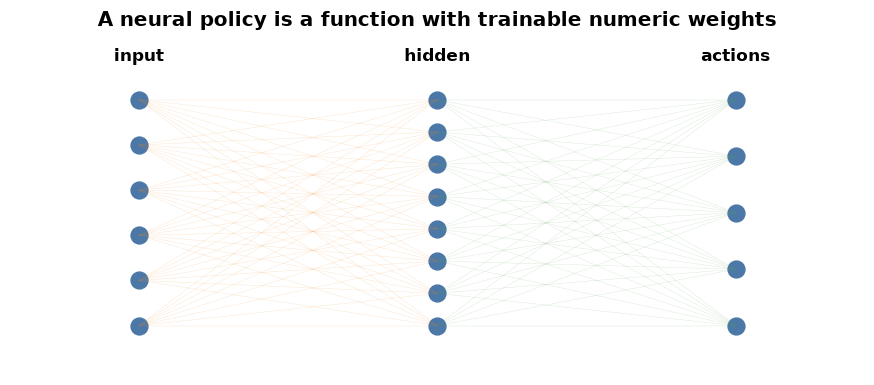

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
repo = Path.cwd()
if repo.name == "notebooks": repo = repo.parent
sys.path.insert(0, str(repo))
from visuals import COLORS

from eldermist import ElderMistReplicaEnv, ACTIONS
from eldermist.policies import sensible_rule_policy
from eldermist.mlp_clone import TinyMLP

# One synthetic architecture picture as an actual figure.
plt.figure(figsize=(10,4))
for x, count, label in [(0.15,6,"input"),(0.50,8,"hidden"),(0.85,5,"actions")]:
    ys = np.linspace(0.15,0.85,count)
    plt.scatter([x]*count, ys, s=120, color=COLORS["STATE"])
    plt.text(x,0.97,label,ha="center",weight="bold")
for y1 in np.linspace(0.15,0.85,6):
    for y2 in np.linspace(0.15,0.85,8):
        plt.plot([0.15,0.50],[y1,y2],linewidth=0.25,alpha=0.25, color=COLORS["ACTION"])
for y1 in np.linspace(0.15,0.85,8):
    for y2 in np.linspace(0.15,0.85,5):
        plt.plot([0.50,0.85],[y1,y2],linewidth=0.25,alpha=0.25, color=COLORS["REWARD"])
plt.xlim(0,1); plt.ylim(0,1.05); plt.axis("off")
plt.title("A neural policy is a function with trainable numeric weights")
plt.show()

<div style="border-left:10px solid #0F766E;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#0F766E">POLICY</div><div style="font-size:21px;font-weight:800;margin-top:4px">1. Collect demonstration pairs</div></div>

Behavior cloning uses examples:

`observation → demonstrated action`.

This is not RL yet. There is no reward-driven update in this training objective.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-052" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Behavior-cloning dataset</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OBSERVATION X</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-052)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TEACHER POLICY</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-052)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION y</text>
</svg>
</div>


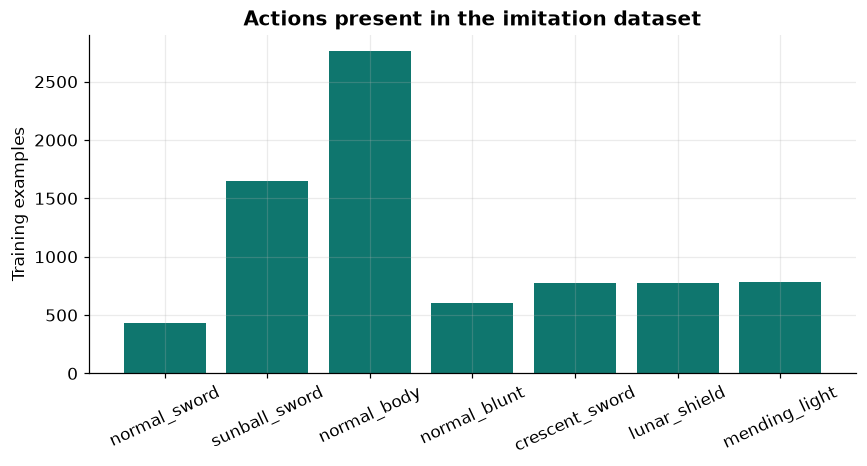

In [2]:
X, y = [], []
for seed in range(200):
    e = ElderMistReplicaEnv()
    o, _ = e.reset(seed=seed)
    while True:
        a = sensible_rule_policy(e, o)
        X.append(o.copy()); y.append(a)
        o, _, term, trunc, _ = e.step(a)
        if term or trunc: break

X = np.asarray(X, float)
y = np.asarray(y, int)

counts = pd.Series(y).value_counts().sort_index()
plt.figure(figsize=(9,4))
plt.bar([ACTIONS[i] for i in counts.index], counts.values, color=COLORS["POLICY"])
plt.xticks(rotation=25)
plt.ylabel("Training examples")
plt.title("Actions present in the imitation dataset")
plt.show()

<div style="border-left:10px solid #E377C2;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#E377C2">WEIGHTS</div><div style="font-size:21px;font-weight:800;margin-top:4px">2. Before training, weights are mostly random</div></div>

The matrix `W1` connects input dimensions to hidden units.

Those values are literally trainable parameters.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-054" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Weights create representation</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">INPUT DIMENSIONS</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-054)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">W₁ MATRIX</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-054)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">HIDDEN REPRESENTATION</text>
</svg>
</div>


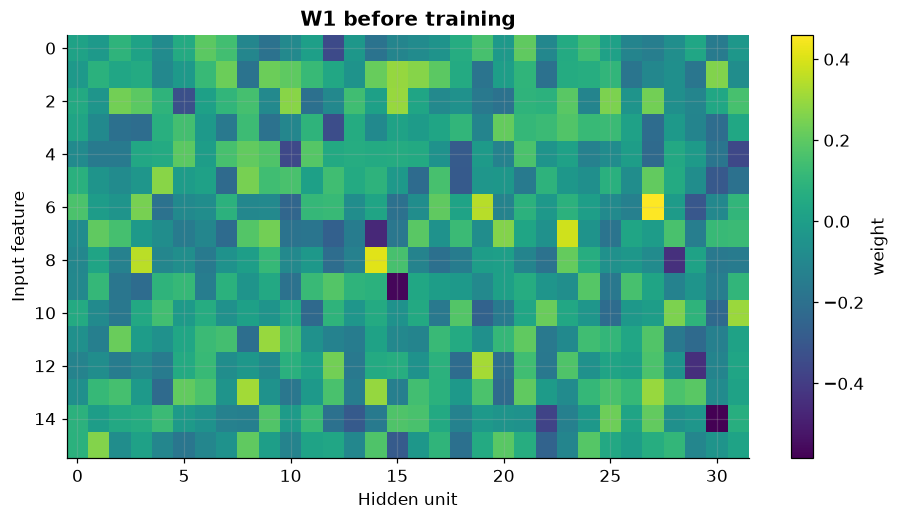

In [3]:
model = TinyMLP(in_dim=X.shape[1], hidden_dim=32, out_dim=len(ACTIONS), seed=0)
before = model.W1.copy()

plt.figure(figsize=(10,5))
plt.imshow(before, aspect="auto")
plt.xlabel("Hidden unit")
plt.ylabel("Input feature")
plt.title("W1 before training")
plt.colorbar(label="weight")
plt.show()

<div style="border-left:10px solid #C026D3;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#C026D3">LOSS</div><div style="font-size:21px;font-weight:800;margin-top:4px">3. Forward pass → loss → backward pass → weight update</div></div>

Backpropagation computes how changing each weight would change the loss.

The optimizer then actually changes the numbers.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-056" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Backprop loop</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">FORWARD PASS</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-056)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#C026D3" stroke="#C026D3" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LOSS</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-056)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#C026D3" stroke="#C026D3" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">GRADIENTS</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-056)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">UPDATE WEIGHTS</text>
</svg>
</div>


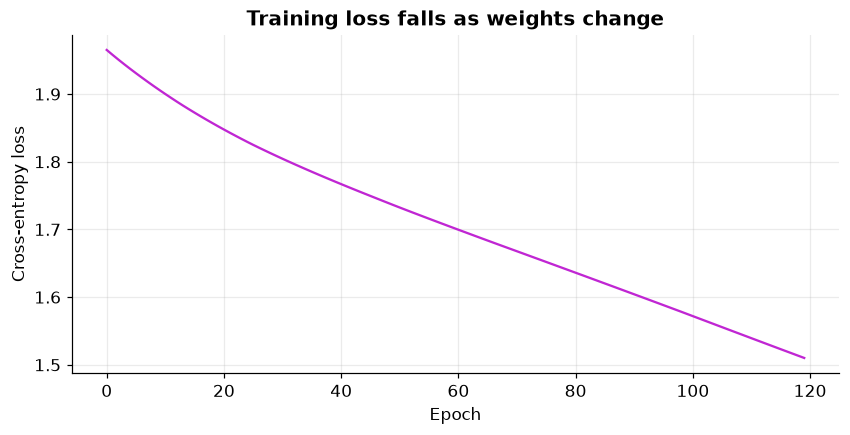

In [4]:
rng = np.random.default_rng(0)
perm = rng.permutation(len(X))
split = int(0.8*len(X))
tr, te = perm[:split], perm[split:]

losses = []
accs = []

for epoch in range(120):
    loss = model.train_step(X[tr], y[tr], lr=0.05)
    losses.append(loss)
    pred = model.predict(X[te])
    accs.append((pred == y[te]).mean())

plt.figure(figsize=(9,4))
plt.plot(losses, color=COLORS["LOSS"])
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training loss falls as weights change")
plt.show()

<div style="border-left:10px solid #E377C2;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#E377C2">WEIGHTS</div><div style="font-size:21px;font-weight:800;margin-top:4px">4. The weights really changed</div></div>

This is different from merely changing a prompt or adding RAG context.

The numeric parameters inside the model are now different.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-058" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Actual parameter learning</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">W BEFORE</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-058)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#C026D3" stroke="#C026D3" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">GRADIENT UPDATE</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-058)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">W AFTER</text>
</svg>
</div>


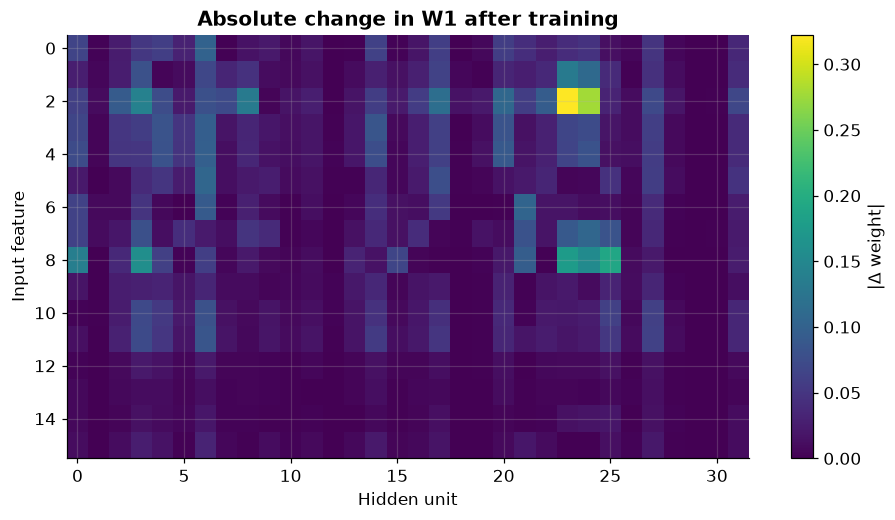

Mean absolute weight change: 0.02474560232237836


In [5]:
after = model.W1.copy()
delta = np.abs(after - before)

plt.figure(figsize=(10,5))
plt.imshow(delta, aspect="auto")
plt.xlabel("Hidden unit")
plt.ylabel("Input feature")
plt.title("Absolute change in W1 after training")
plt.colorbar(label="|Δ weight|")
plt.show()

print("Mean absolute weight change:", delta.mean())

<div style="border-left:10px solid #E377C2;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#E377C2">WEIGHTS</div><div style="font-size:21px;font-weight:800;margin-top:4px">5. What action does the trained network prefer?</div></div>

The final layer produces logits, then softmax converts them to action probabilities.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0510" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Neural policy output</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OBSERVATION</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0510)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NETWORK</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0510)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LOGITS</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0510)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SOFTMAX</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0510)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION PROBS</text>
</svg>
</div>


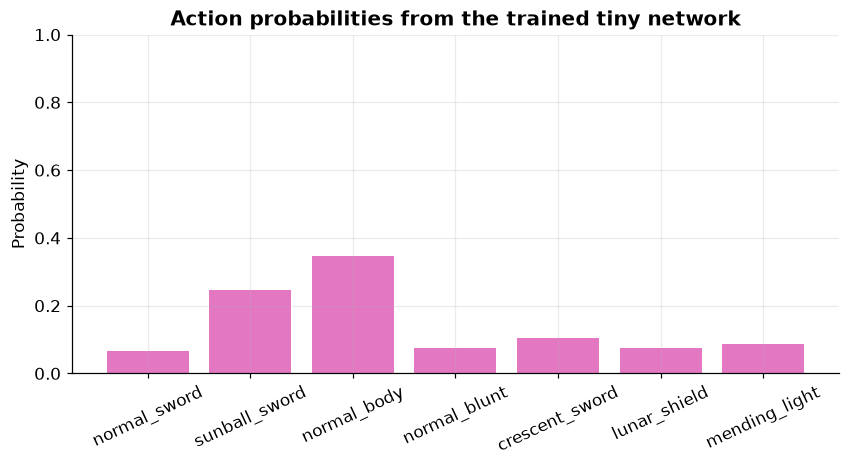

In [6]:
sample = X[te[0:1]]
probs = model.predict_proba(sample)[0]

plt.figure(figsize=(9,4))
plt.bar(ACTIONS, probs, color=COLORS["WEIGHTS"])
plt.xticks(rotation=25)
plt.ylim(0,1)
plt.ylabel("Probability")
plt.title("Action probabilities from the trained tiny network")
plt.show()

<div style="border-left:10px solid #0F766E;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#0F766E">POLICY</div><div style="font-size:21px;font-weight:800;margin-top:4px">6. Behavior cloning vs RL</div></div>

Both can train neural weights.

The difference is the training signal:

- behavior cloning: imitate demonstrated actions
- RL: improve expected future reward from interaction

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0512" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Supervised signal</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">DEMONSTRATION LABEL</text>
<line x1="180.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0512)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BEHAVIOR CLONING</text>
</svg>
</div>


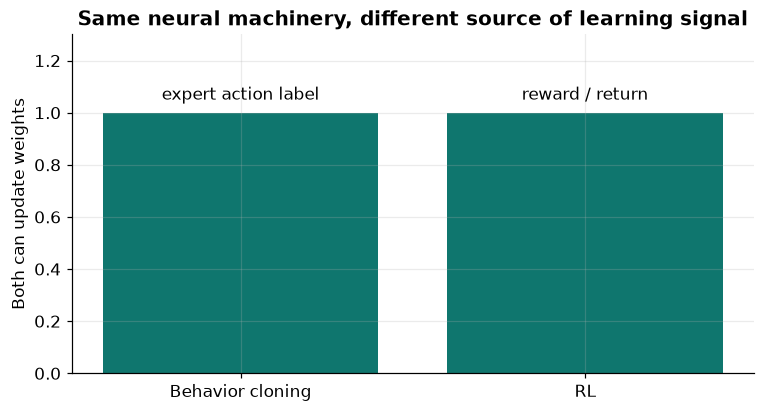

In [7]:
methods = ["Behavior cloning","RL"]
signals = [1,1]
labels = ["expert action label","reward / return"]

plt.figure(figsize=(8,4))
plt.bar(methods, signals, color=COLORS["POLICY"])
plt.ylim(0,1.3)
for i, lab in enumerate(labels):
    plt.text(i, 1.05, lab, ha="center")
plt.ylabel("Both can update weights")
plt.title("Same neural machinery, different source of learning signal")
plt.show()

<div style="border-left:10px solid #64748B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#64748B">KEY IDEA</div><div style="font-size:21px;font-weight:800;margin-top:4px">Once this clicks</div></div>

PPO/OpenAI Five stops being “mysterious neural RL.”

It is a much larger policy/value network whose weights are repeatedly updated using reward-derived objectives from enormous amounts of experience.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0514" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Bridge to large-scale RL</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#8B5CF6" stroke="#8B5CF6" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">EXPERIENCE</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0514)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#C026D3" stroke="#C026D3" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">REWARD-DERIVED LOSS</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0514)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#C026D3" stroke="#C026D3" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BACKPROP</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0514)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#E377C2" stroke="#E377C2" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">WEIGHTS</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0514)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BETTER POLICY</text>
</svg>
</div>
